In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, r2_score
from statsmodels.tsa.arima.model import ARIMA
import joblib
import warnings

from selenium import webdriver
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from selenium.webdriver.chrome.options import Options

warnings.filterwarnings('ignore')
np.random.seed(42)  # For reproducibility

In [4]:
# Path ke ChromeDriver
chrome_driver_path = "/Applications/MAMP/htdocs/local/kodingakademi/Python/python 3/final_ds/chromedriver-mac-arm64/chromedriver"

# Konfigurasi opsi Chrome
options = Options()
options.add_argument("--headless=new")  # Jalankan tanpa membuka jendela browser
options.add_argument("--disable-gpu")   # Mengurangi penggunaan GPU
options.add_argument("--no-sandbox")    # Untuk eksekusi di server tanpa GUI
options.add_argument("--disable-dev-shm-usage")  # Untuk menghindari error pada sistem berbasis Linux

# Inisialisasi WebDriver
service = Service(chrome_driver_path)
driver = webdriver.Chrome(service=service, options=options)

# Buka halaman Yahoo Finance
driver.get("https://finance.yahoo.com/quote/BBCA.JK/history/")

# Tunggu hingga tabel muncul
table = WebDriverWait(driver, 10).until(
    EC.presence_of_element_located((By.CLASS_NAME, "table"))
)

# Ambil semua baris tabel
rows = table.find_elements(By.TAG_NAME, "tr")

data = []
for row in rows:
    cols = row.find_elements(By.TAG_NAME, "td")
    if len(cols) == 7:
        date = cols[0].text 
        open = cols[1].text
        high = cols[2].text 
        low = cols[3].text  
        close = cols[4].text
        adj_close = cols[5].text  
        volume = cols[6].text  
        data.append([date, open, high, low, close, adj_close, volume])

# Simpan dalam DataFrame Pandas
df = pd.DataFrame(data, columns=["Date", "Open", "High", "Low", "Close", "Adj Close", "Volume"])

# Tutup browser
driver.quit()

In [5]:
# =========================
# 1. Preprocessing Data
# =========================
def preprocess_data(df_raw):
    df = df_raw.copy()
    df['Date'] = df['Date'].astype(str)
    df = df[df['Date'].str.match(r'^[A-Za-z]{3,} \d{1,2}, \d{4}$', na=False)]
    df['Date'] = pd.to_datetime(df['Date'], format='%b %d, %Y')
    cols = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
    for col in cols:
        df[col] = df[col].str.replace(',', '', regex=False).astype(float)
    df = df.sort_values('Date').reset_index(drop=True)
    return df

# =========================
# 2. Indikator Teknikal
# =========================
def add_technical_indicators(df):
    df = df.copy()
    df['MA_5'] = df['Close'].rolling(window=5).mean()
    df['MA_10'] = df['Close'].rolling(window=10).mean()
    df['EMA_12'] = df['Close'].ewm(span=12, adjust=False).mean()
    df['EMA_26'] = df['Close'].ewm(span=26, adjust=False).mean()
    df['MACD'] = df['EMA_12'] - df['EMA_26']
    df['Momentum'] = df['Close'] - df['Close'].shift(1)
    df['Volatility_5'] = df['Close'].rolling(window=5).std()
    df['Price_Range'] = df['High'] - df['Low']
    delta = df['Close'].diff()
    gain = np.where(delta > 0, delta, 0)
    loss = np.where(delta < 0, -delta, 0)
    avg_gain = pd.Series(gain).rolling(window=14).mean()
    avg_loss = pd.Series(loss).rolling(window=14).mean()
    rs = avg_gain / (avg_loss + 1e-10)
    df['RSI'] = 100 - (100 / (1 + rs))
    df.dropna(inplace=True)
    return df

# =========================
# 3. Remove Outlier (IQR)
# =========================
def remove_outliers_iqr(df, columns):
    df_out = df.copy()
    for column in columns:
        Q1 = df_out[column].quantile(0.25)
        Q3 = df_out[column].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        df_out = df_out[(df_out[column] >= lower) & (df_out[column] <= upper)]
    return df_out.reset_index(drop=True)

# =========================
# 4. Buat Lag Features Multivariate
# =========================
def create_multivariate_lag_features(df, target_cols, feature_cols, window):
    lagged_features = []
    for col in feature_cols:
        for i in range(1, window + 1):
            lagged_features.append(df[col].shift(i).rename(f'{col}_lag_{i}'))
    df_lag = pd.concat(lagged_features, axis=1)
    target_data = df[target_cols].copy()
    df_lag = pd.concat([df_lag, target_data], axis=1)
    df_lag.dropna(inplace=True)
    return df_lag

# =========================
# 5. Grid Search Lag
# =========================
def grid_search_best_lag(df, target_cols, feature_cols, test_size=7, window_options=[i + 1 for i in range(20)]):
    df = df.reset_index(drop=True)
    df_train = df[:-test_size]
    results = []
    for window in window_options:
        df_ml = create_multivariate_lag_features(df_train, target_cols, feature_cols, window)
        if df_ml.shape[0] == 0:
            continue
        X = df_ml.drop(columns=target_cols)
        y = df_ml[target_cols]
        tscv = TimeSeriesSplit(n_splits=5)
        val_rmses = []
        for train_idx, val_idx in tscv.split(X):
            x_train, x_val = X.iloc[train_idx], X.iloc[val_idx]
            y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
            scaler_x = MinMaxScaler()
            scaler_y = MinMaxScaler()
            x_train_scaled = scaler_x.fit_transform(x_train)
            x_val_scaled = scaler_x.transform(x_val)
            y_train_scaled = scaler_y.fit_transform(y_train)
            y_val_scaled = scaler_y.transform(y_val)
            model = MultiOutputRegressor(XGBRegressor(
                objective='reg:squarederror',
                n_estimators=100,
                learning_rate=0.1,
                max_depth=5,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=42
            ))
            model.fit(x_train_scaled, y_train_scaled)
            y_pred_val = model.predict(x_val_scaled)
            rmse = np.sqrt(mean_squared_error(y_val_scaled, y_pred_val))
            val_rmses.append(rmse)
        avg_rmse = np.mean(val_rmses)
        results.append((window, avg_rmse))
    return results

def plot_grid_results(results):
    windows, rmses = zip(*results)
    plt.figure(figsize=(10, 5))
    plt.plot(windows, rmses, marker='o')
    plt.title("Evaluasi Jumlah Lag berdasarkan TimeSeries RMSE")
    plt.xlabel("Jumlah Lag (window)")
    plt.ylabel("RMSE rata-rata")
    plt.xticks(windows)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# =========================
# 6. Rolling Forecast (Prophet)
# =========================
def rolling_forecast_prophet(df, n_future=7, last_n_days=3):
    from prophet import Prophet
    dfp = df[['Date', 'Close']].rename(columns={'Date': 'ds', 'Close': 'y'})
    model = Prophet(daily_seasonality=True, yearly_seasonality=True)
    model.fit(dfp)
    future = model.make_future_dataframe(periods=n_future)
    forecast = model.predict(future)
    pred = forecast[['ds', 'yhat']].set_index('ds')[-n_future:]['yhat'].values
    # Plot
    last_n_dates = df['Date'].iloc[-last_n_days:].tolist()
    last_n_close = df['Close'].iloc[-last_n_days:].tolist()
    last_date = df['Date'].iloc[-1]
    future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_future, freq='D').tolist()
    plt.figure(figsize=(12, 5))
    plt.plot(last_n_dates, last_n_close, label=f'Actual (Last {last_n_days} Days)', marker='o')
    plt.plot(future_dates, pred, label='Prophet Forecast', marker='o', color='red')
    plt.axvspan(future_dates[0], future_dates[-1], color='orange', alpha=0.1, label='Forecast Area')
    plt.title(f'Rolling Forecast Close Price (Prophet)')
    plt.xlabel('Date'); plt.ylabel('Close Price')
    plt.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()
    # Evaluasi
    y_true = df['Close'].iloc[-n_future:].values if len(df) >= n_future else None
    if y_true is not None:
        mape = mean_absolute_percentage_error(y_true, pred)
        r2 = r2_score(y_true, pred)
        print(f"[Prophet Rolling] MAPE: {mape:.2%}, R²: {r2:.3f}")
    return pred

# =========================
# 7. Rolling Forecast (ARIMA)
# =========================
def rolling_forecast_arima(df, n_future=7, last_n_days=3, order=(7, 1, 0)):
    series = df['Close']
    model = ARIMA(series, order=order)
    fit = model.fit()
    forecast = fit.forecast(steps=n_future)
    pred = forecast.values
    # Plot
    last_n_dates = df['Date'].iloc[-last_n_days:].tolist()
    last_n_close = df['Close'].iloc[-last_n_days:].tolist()
    last_date = df['Date'].iloc[-1]
    future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_future, freq='D').tolist()
    plt.figure(figsize=(12, 5))
    plt.plot(last_n_dates, last_n_close, label=f'Actual (Last {last_n_days} Days)', marker='o')
    plt.plot(future_dates, pred, label='ARIMA Forecast', marker='o', color='green')
    plt.axvspan(future_dates[0], future_dates[-1], color='orange', alpha=0.1, label='Forecast Area')
    plt.title(f'Rolling Forecast Close Price (ARIMA)')
    plt.xlabel('Date'); plt.ylabel('Close Price')
    plt.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()
    # Evaluasi
    y_true = df['Close'].iloc[-n_future:].values if len(df) >= n_future else None
    if y_true is not None:
        mape = mean_absolute_percentage_error(y_true, pred)
        r2 = r2_score(y_true, pred)
        print(f"[ARIMA Rolling] MAPE: {mape:.2%}, R²: {r2:.3f}")
    return pred

# =========================
# 8. Rolling Forecast (XGBoost - Long Lag)
# =========================
def walk_forward_forecast_longlag(model, df, scaler_x, scaler_y, target_cols, feature_base, selected_lags, window, n_future):
    last_df = df[feature_base].iloc[-window:].copy()
    forecasts = []
    for step in range(n_future):
        lag_data = {}
        for feat in selected_lags:
            col_name, lag_num = feat.rsplit('_lag_', 1)
            lag_data[feat] = last_df[col_name].iloc[-int(lag_num)]
        input_df = pd.DataFrame([lag_data])
        input_scaled = scaler_x.transform(input_df)
        pred_scaled = model.predict(input_scaled)[0]
        pred_unscaled = scaler_y.inverse_transform([pred_scaled])[0]
        forecasts.append(pred_unscaled)
        next_row = dict(zip(target_cols, pred_unscaled))
        last_df = pd.concat([last_df, pd.DataFrame([next_row])], ignore_index=True)
    return np.array(forecasts)

# =========================
# 9. Evaluasi & Visualisasi Perbandingan
# =========================
def compare_forecast_plot(df_clean, forecast_xgb, forecast_arima, forecast_prophet, n_future=7, last_n_days=3):
    last_n_dates = df_clean['Date'].iloc[-last_n_days:].tolist()
    last_n_close = df_clean['Close'].iloc[-last_n_days:].tolist()
    last_date = df_clean['Date'].iloc[-1]
    future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_future, freq='D').tolist()
    plt.figure(figsize=(13, 5))
    plt.plot(last_n_dates, last_n_close, label=f'Actual (Last {last_n_days} Days)', linestyle='-', marker='o', color='C0')
    plt.plot(future_dates, forecast_xgb[:, 0], label='XGBoost Forecast', marker='o', color='C1')
    plt.plot(future_dates, forecast_arima, label='ARIMA Forecast', marker='o', color='C2')
    plt.plot(future_dates, forecast_prophet, label='Prophet Forecast', marker='o', color='C3')
    plt.axvspan(future_dates[0], future_dates[-1], color='orange', alpha=0.08, label='Forecast Area')
    plt.title(f'Perbandingan Forecast Close Price: XGBoost vs ARIMA vs Prophet')
    plt.xlabel('Date'); plt.ylabel('Close Price')
    plt.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

In [6]:
# 1. Preprocessing
df_clean = preprocess_data(df)
df_clean = add_technical_indicators(df_clean)
df_clean = remove_outliers_iqr(df_clean, ['Close', 'Open', 'High', 'Low', 'Volume'])

In [7]:
# 2. Setup fitur & target
target_columns = ['Close']
feature_columns = ['Open', 'High', 'Low','MA_5', 'MA_10', 'EMA_12', 'EMA_26', 'MACD', 'Momentum', 'Volatility_5', 'Price_Range', 'RSI']

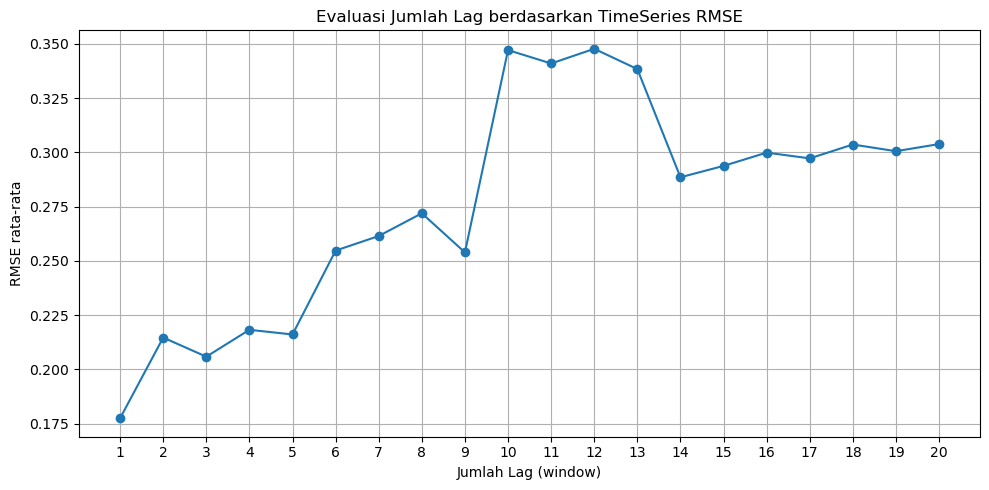

Best window (lag): 1


In [8]:
# 3. Cari window lag optimal
results = grid_search_best_lag(df_clean, target_columns, feature_columns)
plot_grid_results(results)
best_window = min(results, key=lambda x: x[1])[0]
print(f'Best window (lag): {best_window}')

In [9]:
# 4. Dataset machine learning & scaler
window = best_window  # Atur lag history panjang (misal 7 atau 14)
df_ml = create_multivariate_lag_features(df_clean, target_columns, feature_columns, window)
x = df_ml.drop(columns=target_columns)
y = df_ml[target_columns]
scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()
x_scaled = scaler_x.fit_transform(x)
y_scaled = scaler_y.fit_transform(y)

In [10]:
# 5. Force semua lag untuk rolling longlag
selected_features = []
for col in feature_columns:
    for i in range(1, window+1):
        lag_feat = f"{col}_lag_{i}"
        if lag_feat in x.columns:
            selected_features.append(lag_feat)
x_selected = x[selected_features]
scaler_x_sel = StandardScaler()
x_selected_scaled = scaler_x_sel.fit_transform(x_selected)
model_sel = MultiOutputRegressor(XGBRegressor(
    objective='reg:squarederror',
    n_estimators=200,
    learning_rate=0.08,
    max_depth=4,
    subsample=0.9,
    colsample_bytree=0.8,
    reg_alpha=3.0,
    reg_lambda=8.0,
    random_state=42
))
model_sel.fit(x_selected_scaled, y_scaled)

MultiOutputRegressor(estimator=XGBRegressor(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=0.8, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_metric=None,
                                            feature_types=None,
                                            feature_weights=None, gamma=None,
                                            grow_policy=None,
                                            importance_type=None,
                                            interaction_constraints=None,
                                            learning_rate=0.08, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=4,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=200, n_jobs=None,
                                            num_parallel_tree=None, ...))

13:48:46 - cmdstanpy - INFO - Chain [1] start processing
13:48:46 - cmdstanpy - INFO - Chain [1] done processing


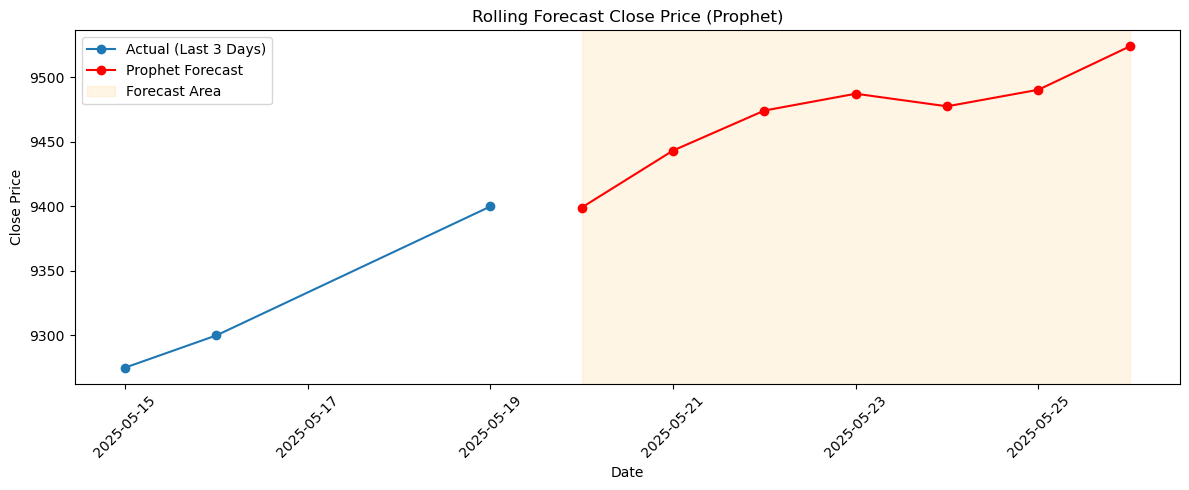

[Prophet Rolling] MAPE: 3.13%, R²: -3.139


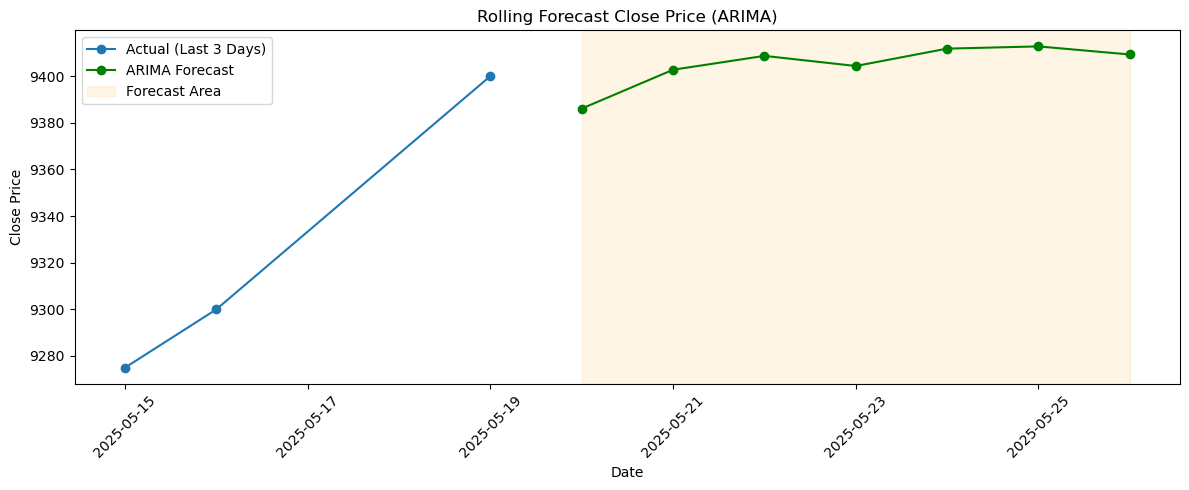

[ARIMA Rolling] MAPE: 2.42%, R²: -1.980


In [11]:
# 6. Rolling Forecast
n_future = 7
forecast_xgb = walk_forward_forecast_longlag(
    model_sel, df_clean, scaler_x_sel, scaler_y, target_columns, feature_columns, selected_features, window, n_future
)
forecast_prophet = rolling_forecast_prophet(df_clean, n_future=n_future, last_n_days=3)
forecast_arima = rolling_forecast_arima(df_clean, n_future=n_future, last_n_days=3)

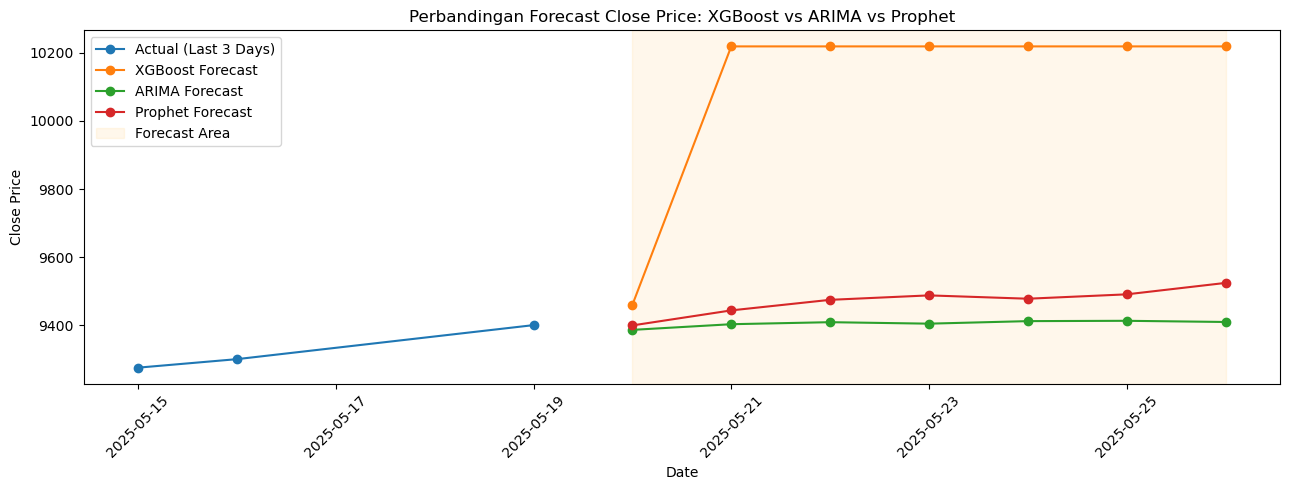

In [12]:
# 7. Evaluasi & Visualisasi Perbandingan
compare_forecast_plot(df_clean, forecast_xgb, forecast_arima, forecast_prophet, n_future=n_future, last_n_days=3)